In [1]:
import pandas as pd
import numpy as np

In [2]:
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv
from getpass import getpass

# Load the .env file
load_dotenv()

# Read database credentials
user = os.getenv("DB_USER","root")
password = os.getenv("Charan@123")
host = os.getenv("DB_HOST","localhost")
database = os.getenv("DB_NAME","cart2insights")
port = int(os.getenv("DB_PORT","3306"))

# Check whether the password is availble
if not password:
    password = getpass(
    "Enter your MYSQL password: ")

#Create the MYSQL connection URL
connection_url = URL.create(
    drivername="mysql+pymysql",
    username='root',
    password='Charan@123',
    host='127.0.0.1',
    port=3306,
    database='cart2insights'
)

#create MYSQL connection

engine = create_engine(connection_url)

#Test the connection
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT DATABASE()"))
        connected_database = result.scalar()
        print("Database connection successful!")
        print("Connected database:", connected_database)
except Exception as error:
    print("Database connection failed!")
    print("Error details:", error)
finally:
    engine.dispose()

Enter your MYSQL password:  ········


Database connection successful!
Connected database: cart2insights


In [3]:
customers = pd.read_sql("SELECT * FROM customers", engine)

In [4]:
orders = pd.read_sql("SELECT * FROM orders", engine)


In [5]:
order_items = pd.read_sql("SELECT * FROM order_items", engine)


In [6]:
products = pd.read_sql("SELECT * FROM products", engine)


In [7]:
payments = pd.read_sql("SELECT * FROM payments", engine)


In [8]:
reviews = pd.read_sql("SELECT * FROM reviews", engine)


In [9]:
sellers = pd.read_sql("SELECT * FROM sellers", engine)

In [34]:
category_translation = pd.read_sql("SELECT * FROM category_translation", engine)

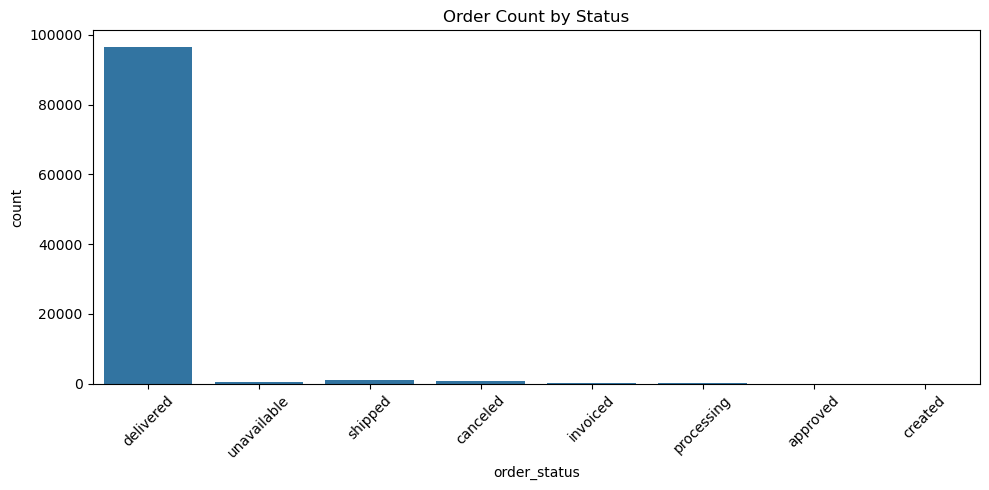

In [10]:
# Order status distribution Chart

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=orders,
    x="order_status"
)

plt.xticks(rotation=45)
plt.title("Order Count by Status")
plt.tight_layout()
plt.show()

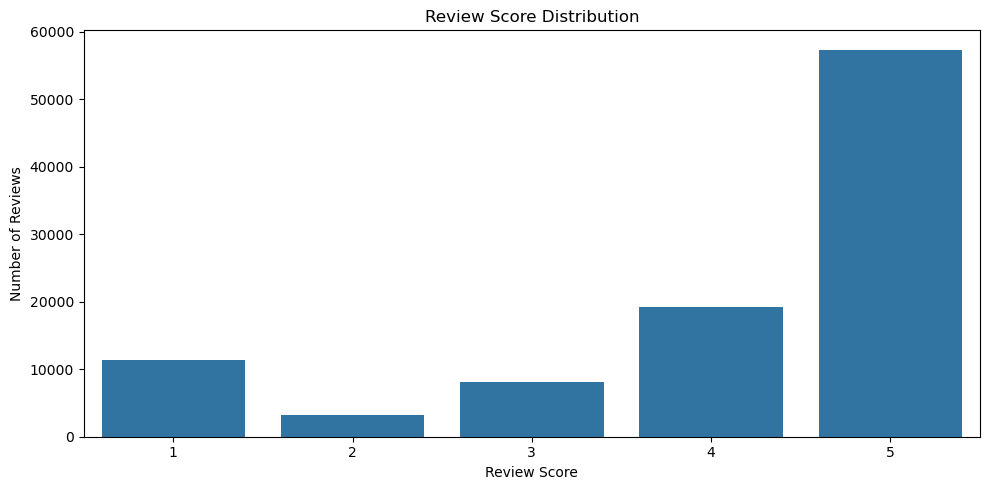

In [11]:
# Review score distribution Chart

plt.figure(figsize=(10, 5))

sns.countplot(
    data=reviews,
    x="review_score",
    order=[1, 2, 3, 4, 5]
)

plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.title("Review Score Distribution")
plt.tight_layout()
plt.show()

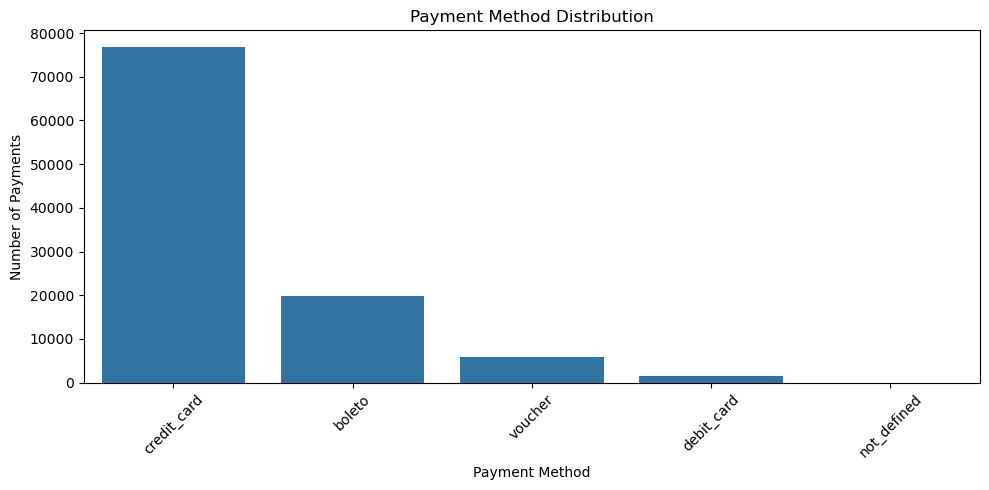

In [12]:
# Payment method distribution Chart

plt.figure(figsize=(10, 5))

sns.countplot(
    data=payments,
    x="payment_type"
)

plt.xticks(rotation=45)
plt.xlabel("Payment Method")
plt.ylabel("Number of Payments")
plt.title("Payment Method Distribution")
plt.tight_layout()
plt.show()

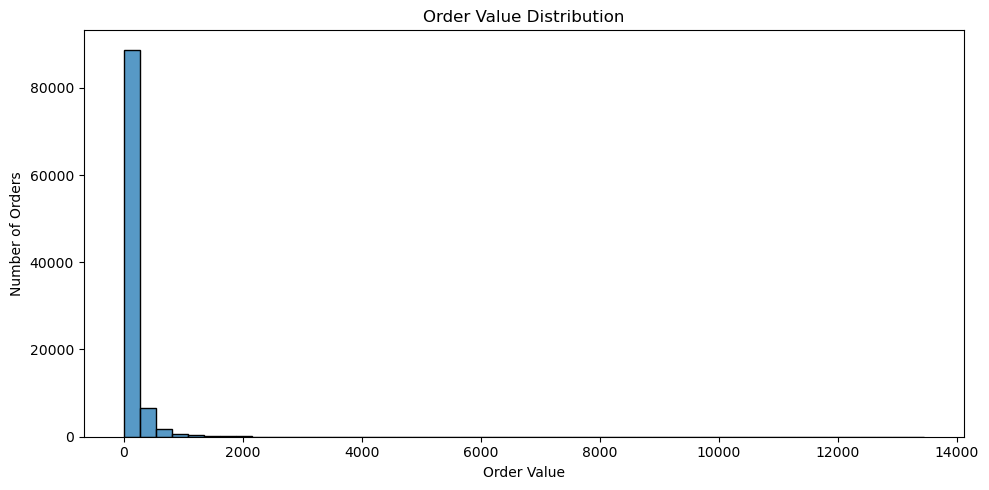

In [13]:
# Order value distribution Chart


# Calculate total value for each order
order_totals = (
    order_items.groupby('order_id')['price']
    .sum()
    .reset_index(name='order_value')
)

# Create chart
plt.figure(figsize=(10, 5))

sns.histplot(
    data=order_totals,
    x="order_value",
    bins=50
)

plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.title("Order Value Distribution")
plt.tight_layout()
plt.show()

In [14]:
delivery_reviews = orders.merge(
    reviews[['order_id', 'review_score']],
    on='order_id'
)

delivery_reviews.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,5
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,4
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,5
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,4
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,5


In [15]:
# Create Delivery Groups

# Convert columns into datetime
delivery_reviews['order_delivered_customer_date'] = pd.to_datetime(
    delivery_reviews['order_delivered_customer_date']
)

delivery_reviews['order_estimated_delivery_date'] = pd.to_datetime(
    delivery_reviews['order_estimated_delivery_date']
)

# Remove records without delivery dates
delivery_reviews = delivery_reviews.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'review_score'
    ]
)

# Create delivery groups
delivery_reviews['delivery_group'] = (
    delivery_reviews['order_delivered_customer_date']
    <= delivery_reviews['order_estimated_delivery_date']
).map({
    True: 'On Time',
    False: 'Delayed'
})

delivery_reviews.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,delivery_group
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,5,On Time
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,4,On Time
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,5,On Time
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,4,On Time
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,5,On Time


In [16]:
# Calculate Average Review Score


average_review = (
    delivery_reviews.groupby('delivery_group')['review_score']
    .mean()
    .reset_index(name='average_review_score')
)

print(average_review)

  delivery_group  average_review_score
0        Delayed              2.566550
1        On Time              4.293578


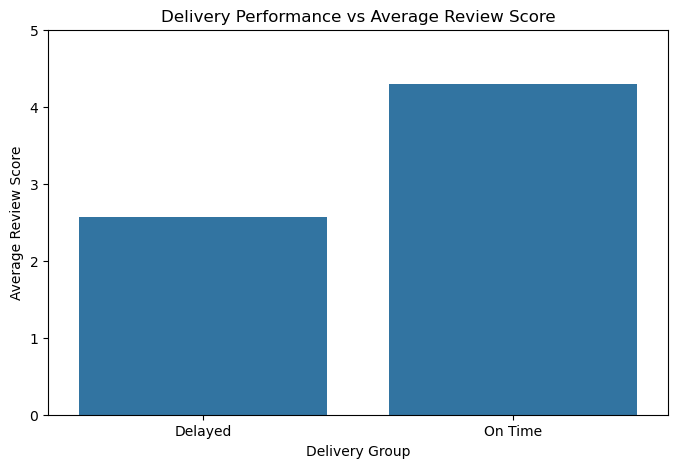

In [21]:
# Visualize Using Bar Chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=average_review,
    x='delivery_group',
    y='average_review_score'
)

plt.title('Delivery Performance vs Average Review Score')
plt.xlabel('Delivery Group')
plt.ylabel('Average Review Score')

plt.ylim(0, 5)
plt.show()

In [22]:
# Save Analysis Results

import os

# Step 1: Create cleaned folder if it does not exist
os.makedirs('cleaned', exist_ok=True)

# Step 2: Save the analysis results
average_review.to_csv(
    'cleaned/delivery_review_analysis.csv',
    index=False
)

print("Bivariate analysis completed successfully!")

Bivariate analysis completed successfully!


In [ ]:
# This displays your current working directory.

import os

print(os.getcwd())

In [23]:
#Trend Analysis – Monthly Sales

# Calculate Total Order Value

order_totals = (
    order_items.groupby('order_id')['price']
    .sum()
    .reset_index(name='order_value')
)

order_totals.head()



,order_id,order_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [25]:
# Join OrderTotals with Orders

monthly_orders = orders.merge(
    order_totals,
    on='order_id'
)

monthly_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_value
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,58.90
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,239.90
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,199.00
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,199.90


In [27]:
# Extract Purchase Month

# Convert timestamp into datetime
monthly_orders['order_purchase_timestamp'] = pd.to_datetime(
    monthly_orders['order_purchase_timestamp']
)

# Extract year and month
monthly_orders['purchase_month'] = (
    monthly_orders['order_purchase_timestamp']
    .dt.to_period('M')
)

In [29]:
# Calculate Monthly Sales

monthly_sales = (
    monthly_orders.groupby('purchase_month')['order_value']
    .sum()
    .reset_index(name='total_sales')
)

# Convert month into string for visualization
monthly_sales['purchase_month'] = (
    monthly_sales['purchase_month'].astype(str)
)

print(monthly_sales)

   purchase_month  total_sales
0         2016-09       267.36
1         2016-10     49507.66
2         2016-12        10.90
3         2017-01    120312.87
4         2017-02    247303.02
5         2017-03    374344.30
6         2017-04    359927.23
7         2017-05    506071.14
8         2017-06    433038.60
9         2017-07    498031.48
10        2017-08    573971.68
11        2017-09    624401.69
12        2017-10    664219.43
13        2017-11   1010271.37
14        2017-12    743914.17
15        2018-01    950030.36
16        2018-02    844178.71
17        2018-03    983213.44
18        2018-04    996647.75
19        2018-05    996517.68
20        2018-06    865124.31
21        2018-07    895507.22
22        2018-08    854686.33
23        2018-09       145.00


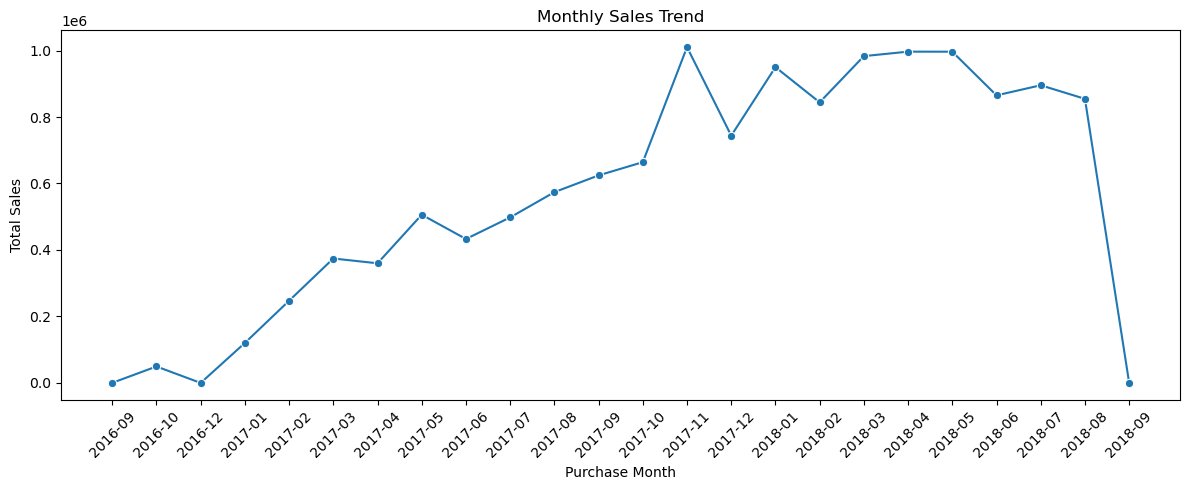

In [31]:
# Monthly Sales Trend Line Chart

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x='purchase_month',
    y='total_sales',
    marker='o'
)

plt.xticks(rotation=45)

plt.xlabel("Purchase Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")

plt.tight_layout()
plt.show()

In [32]:
import os

os.makedirs('cleaned', exist_ok=True)

monthly_sales.to_csv(
    'cleaned/monthly_sales_trend.csv',
    index=False
)

print("Monthly sales trend analysis completed successfully!")

Monthly sales trend analysis completed successfully!


In [35]:
#Join Required Tables  ( Join order_items with products and category_translation)
category_data = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id'
)

category_data = category_data.merge(
    category_translation,
    on='product_category_name'
)

category_data.head()


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [36]:
#Revenue by Category (Calculate total revenue using the price column)

category_revenue = (
    category_data.groupby('product_category_name_english')['price']
    .sum()
    .reset_index(name='total_revenue')
    .sort_values('total_revenue', ascending=False)
)

print(category_revenue.head(10))


   product_category_name_english  total_revenue
44                 health_beauty     1258681.34
73                 watches_gifts     1205005.68
8                 bed_bath_table     1036988.68
68                sports_leisure      988048.97
16         computers_accessories      911954.32
40               furniture_decor      729762.49
21                    cool_stuff      635290.85
50                    housewares      632248.66
6                           auto      592720.11
43                  garden_tools      485256.46


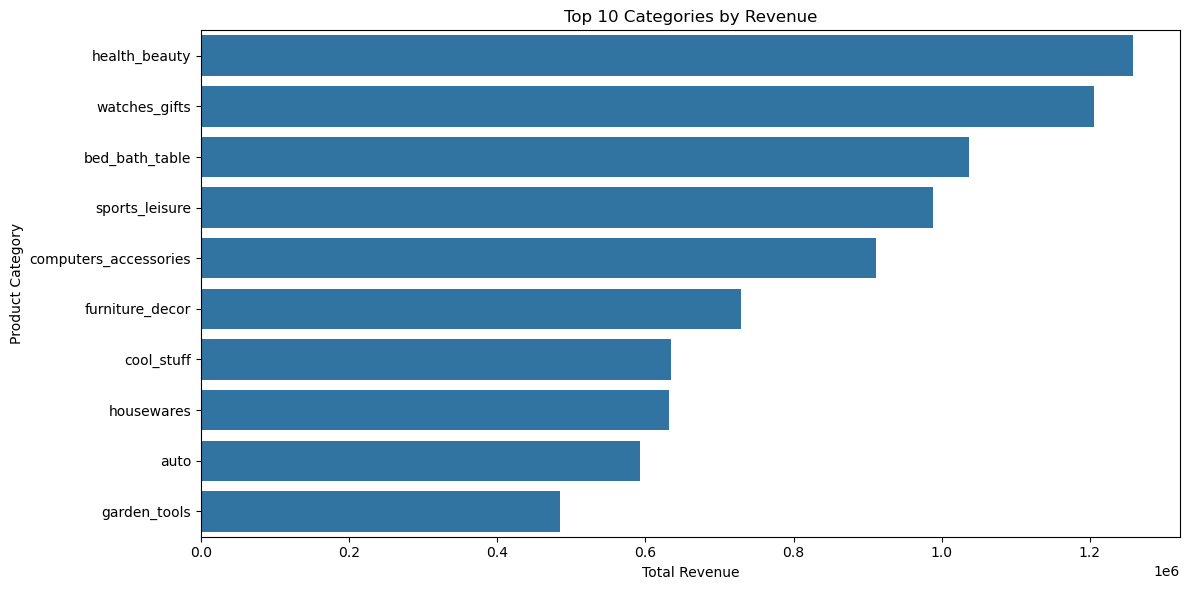

In [37]:
#Top 10 Categories by Revenue

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue.head(10),
    x='total_revenue',
    y='product_category_name_english'
)

plt.title("Top 10 Categories by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [39]:
#Item Quantities by Category Since your order_items table does not contain a quantity column, count each order-item row as one item.

category_quantity = (
    category_data.groupby('product_category_name_english')
    .size()
    .reset_index(name='total_items')
    .sort_values('total_items', ascending=False)
)

print(category_quantity.head(10))

   product_category_name_english  total_items
8                 bed_bath_table        11115
44                 health_beauty         9670
68                sports_leisure         8641
40               furniture_decor         8334
16         computers_accessories         7827
50                    housewares         6964
73                 watches_gifts         5991
71                     telephony         4545
43                  garden_tools         4347
6                           auto         4235


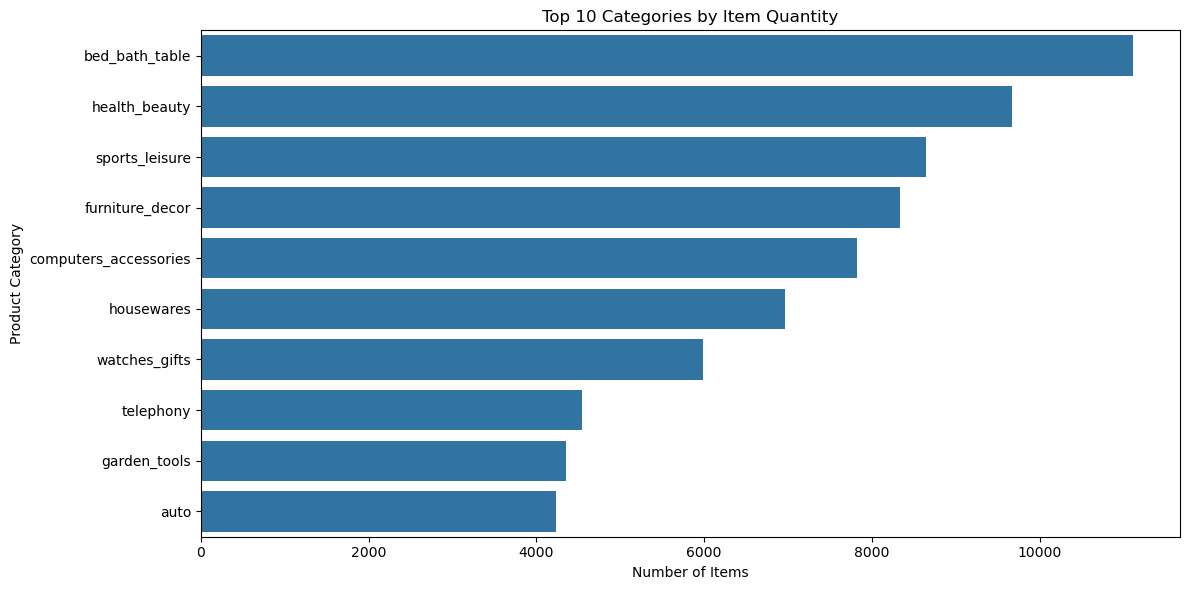

In [40]:
#Top 10 Categories by Item Quantity

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_quantity.head(10),
    x='total_items',
    y='product_category_name_english'
)

plt.title("Top 10 Categories by Item Quantity")
plt.xlabel("Number of Items")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [41]:
#Average Item Value by Category Calculate the average selling price for each category

category_avg_value = (
    category_data.groupby('product_category_name_english')['price']
    .mean()
    .reset_index(name='average_item_value')
    .sort_values('average_item_value', ascending=False)
)

print(category_avg_value.head(10))


                    product_category_name_english  average_item_value
15                                      computers         1098.340542
67          small_appliances_home_oven_and_coffee          624.285658
46                              home_appliances_2          476.124958
1                      agro_industry_and_commerce          342.124858
58                            musical_instruments          281.616000
66                               small_appliances          280.778468
52  kitchen_appliances_and_food_preparation_tools          264.568667
35                                fixed_telephony          225.693182
20                      construction_tools_safety          208.992371
73                                  watches_gifts          201.135984


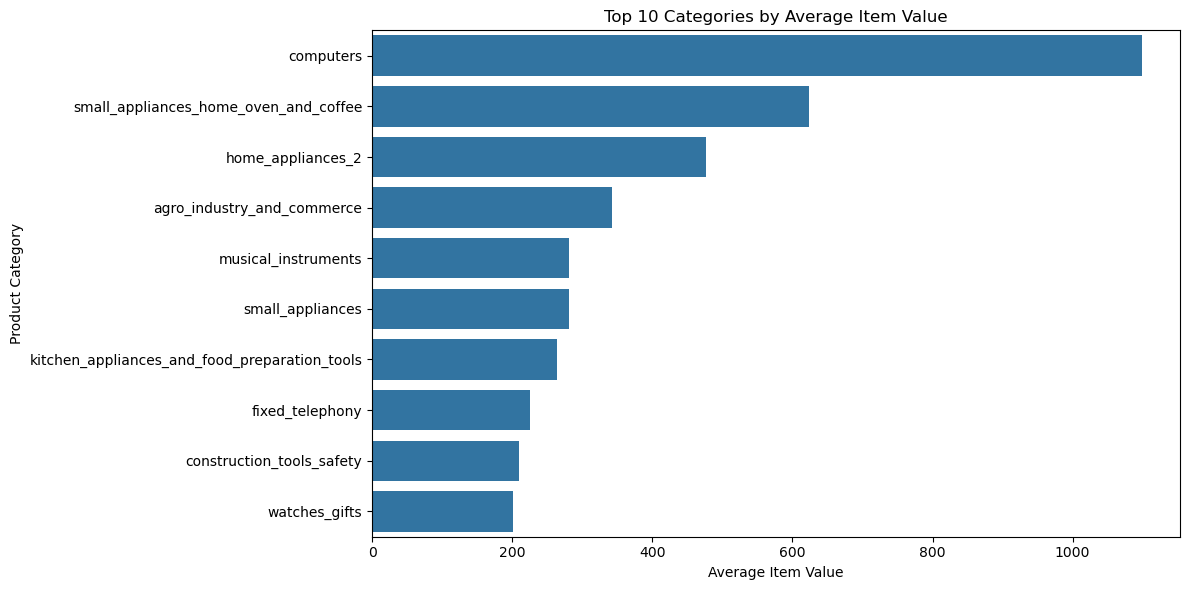

In [42]:
# Average Item Value by Category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_avg_value.head(10),
    x='average_item_value',
    y='product_category_name_english'
)

plt.title("Top 10 Categories by Average Item Value")
plt.xlabel("Average Item Value")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [44]:
#Review Scores by Category Join category data with customer reviews using order_id.

# Create unique order-category combinations
order_categories = category_data[
    ['order_id', 'product_category_name_english']
].drop_duplicates()

# Calculate one average review score per order
order_review_scores = (
     reviews.groupby('order_id')['review_score']
    .mean()
    .reset_index()
)

# Join reviews with categories
category_reviews = order_categories.merge(
    order_review_scores,
    on='order_id'
)

# Calculate average review score by category
category_review_score = (
    category_reviews.groupby('product_category_name_english')['review_score']
    .mean()
    .reset_index(name='average_review_score')
    .sort_values('average_review_score', ascending=False)
)

print(category_review_score.head(10))

            product_category_name_english  average_review_score
12                      cds_dvds_musicals              4.666667
30              fashion_childrens_clothes              4.500000
9                  books_general_interest              4.462598
23                costruction_tools_tools              4.425532
11                        books_technical              4.400778
36                                flowers              4.392857
38                             food_drink              4.382743
55                    luggage_accessories              4.331068
10                         books_imported              4.320755
67  small_appliances_home_oven_and_coffee              4.293333


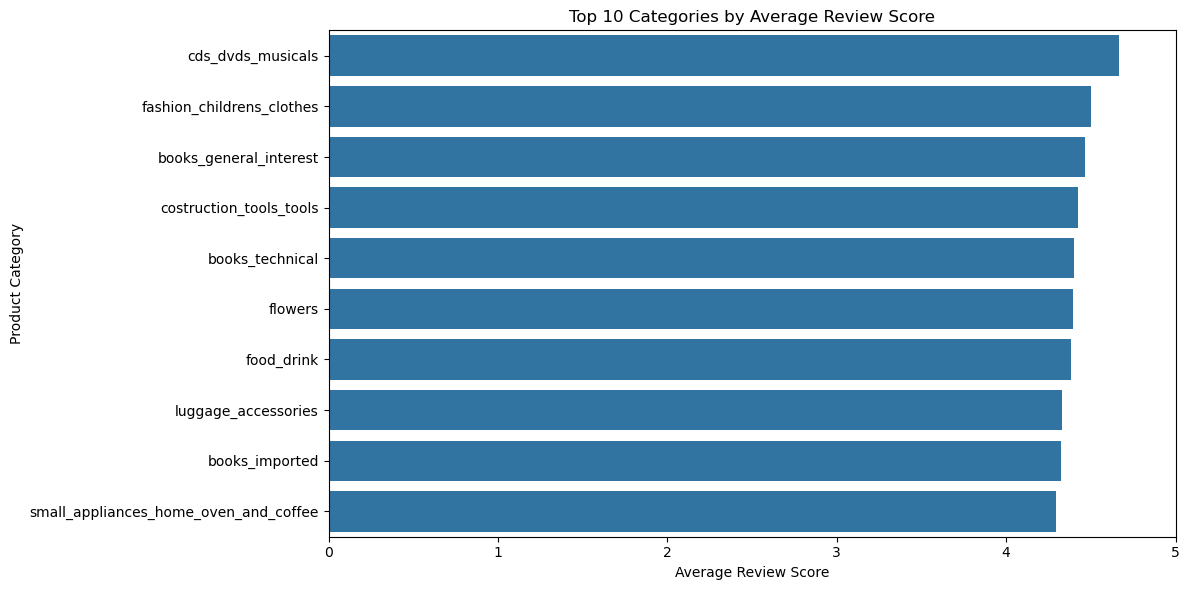

In [45]:
# Top 10 Categories by Average Review Score

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_review_score.head(10),
    x='average_review_score',
    y='product_category_name_english'
)

plt.title("Top 10 Categories by Average Review Score")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


In [46]:
#Combine All Four Analyses
category_summary = category_revenue.merge(
    category_quantity,
    on='product_category_name_english'
)

category_summary = category_summary.merge(
    category_avg_value,
    on='product_category_name_english'
)

category_summary = category_summary.merge(
    category_review_score,
    on='product_category_name_english'
)

category_summary.head(10)


,product_category_name_english,total_revenue,total_items,average_item_value,average_review_score
0,health_beauty,1258681.34,9670,130.163531,4.181203
1,watches_gifts,1205005.68,5991,201.135984,4.065459
2,bed_bath_table,1036988.68,11115,93.296327,3.970740
3,sports_leisure,988048.97,8641,114.344285,4.167362
4,computers_accessories,911954.32,7827,116.513903,4.026245
5,furniture_decor,729762.49,8334,87.564494,4.009691
6,cool_stuff,635290.85,3796,167.357969,4.169630
7,housewares,632248.66,6964,90.788148,4.142221
8,auto,592720.11,4235,139.957523,4.090147
9,garden_tools,485256.46,4347,111.630196,4.136156


In [47]:
# Save Analysis Results

os.makedirs('cleaned', exist_ok=True)

category_summary.to_csv(
    'cleaned/category_analysis.csv',
    index=False
)

print("Category analysis completed successfully!")

Category analysis completed successfully!


In [48]:
# Calculate Order Price and Freight

order_values = (
    order_items.groupby('order_id')
    .agg(
        price=('price', 'sum'),
        freight=('freight_value', 'sum')
    )
    .reset_index()
)

order_values.head()


,order_id,price,freight
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14


In [49]:
# Join Orders with Order Values

correlation_data = orders.merge(
    order_values,
    on='order_id'
)

correlation_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,price,freight
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,199.90,18.14


In [50]:
#Calculate Delivery Time

correlation_data['order_purchase_timestamp'] = pd.to_datetime(
    correlation_data['order_purchase_timestamp']
)

correlation_data['order_delivered_customer_date'] = pd.to_datetime(
    correlation_data['order_delivered_customer_date']
)

correlation_data['delivery_time'] = (
    correlation_data['order_delivered_customer_date']
    - correlation_data['order_purchase_timestamp']
).dt.total_seconds() / 86400

correlation_data.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,price,freight,delivery_time
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,58.90,13.29,7.614421
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,239.90,19.93,16.216181
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,199.00,17.87,7.948437
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,12.99,12.79,6.147269
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,199.90,18.14,25.114352


In [52]:
# Join Review Scores If an order has multiple review records, calculate its average review score before joining.



review_data = (
    reviews.groupby('order_id')['review_score']
    .mean()
    .reset_index()
)

correlation_data = correlation_data.merge(
    review_data,
    on='order_id'
)

correlation_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,price,freight,delivery_time,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,58.90,13.29,7.614421,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,239.90,19.93,16.216181,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,199.00,17.87,7.948437,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,12.99,12.79,6.147269,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,199.90,18.14,25.114352,5.0


In [53]:
#Select Numerical Variables


numerical_data = correlation_data[
    ['price', 'freight', 'delivery_time', 'review_score']
].copy()

# Remove missing values
numerical_data = numerical_data.dropna()

# Exclude invalid negative delivery durations
numerical_data = numerical_data[
    numerical_data['delivery_time'] >= 0
]

numerical_data.head()


,price,freight,delivery_time,review_score
0,58.90,13.29,7.614421,5.0
1,239.90,19.93,16.216181,4.0
2,199.00,17.87,7.948437,5.0
3,12.99,12.79,6.147269,4.0
4,199.90,18.14,25.114352,5.0


In [54]:
#Calculate Correlation Matrix  Use Spearman correlation to measure relationships between the selected variables.


correlation_matrix = numerical_data.corr(
    method='spearman'
)

print(correlation_matrix.round(2))

               price  freight  delivery_time  review_score
price           1.00     0.47           0.10         -0.03
freight         0.47     1.00           0.38         -0.09
delivery_time   0.10     0.38           1.00         -0.23
review_score   -0.03    -0.09          -0.23          1.00


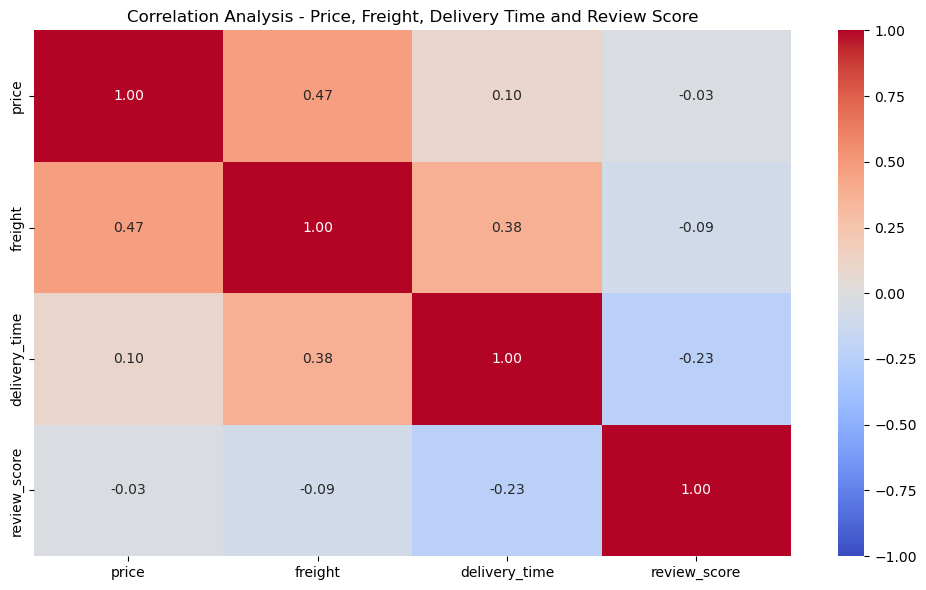

In [55]:
#Create Correlation Heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title("Correlation Analysis - Price, Freight, Delivery Time and Review Score")

plt.tight_layout()
plt.show()


In [56]:
#Save Correlation Results


import os

os.makedirs('cleaned', exist_ok=True)

correlation_matrix.to_csv(
    'cleaned/correlation_analysis.csv'
)

print("Correlation analysis completed successfully!")



Correlation analysis completed successfully!


In [58]:
# Distribution analysis

# Calculate total price and freight at the order level.

# Calculate order-level price and freight
order_values = (
    order_items.groupby('order_id')
    .agg(
        price=('price', 'sum'),
        freight=('freight_value', 'sum')
    )
    .reset_index()
)

# Join with orders
distribution_data = orders.merge(
    order_values,
    on='order_id'
)

distribution_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,price,freight
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,199.90,18.14


In [59]:
#Calculate Delivery Time

# Convert dates into datetime
distribution_data['order_purchase_timestamp'] = pd.to_datetime(
    distribution_data['order_purchase_timestamp']
)

distribution_data['order_delivered_customer_date'] = pd.to_datetime(
    distribution_data['order_delivered_customer_date']
)

# Calculate delivery time in days
distribution_data['delivery_time'] = (
    distribution_data['order_delivered_customer_date']
    - distribution_data['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Remove invalid negative delivery durations
distribution_data.loc[
    distribution_data['delivery_time'] < 0,
    'delivery_time'
] = float('nan')

<Axes: xlabel='price', ylabel='Count'>

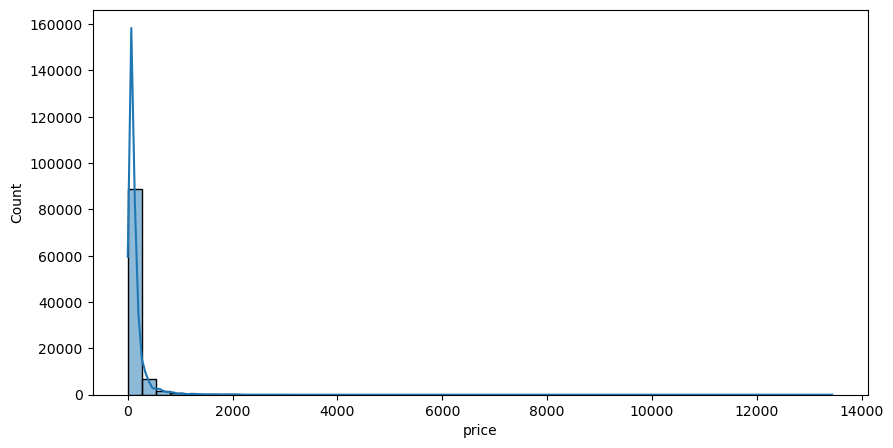

In [60]:
# Price Distribution – Histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    data=distribution_data,
    x='price',
    bins=50,
    kde=True
)


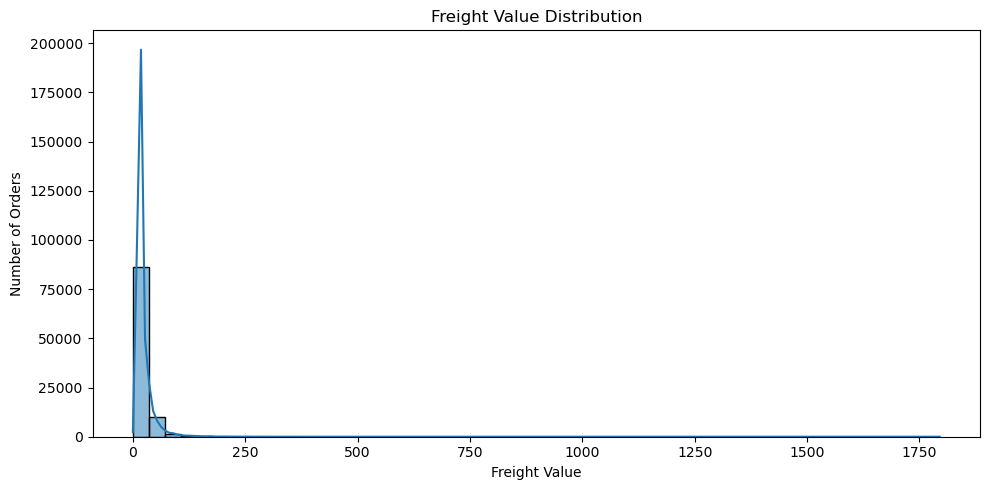

In [61]:
#Freight Distribution – Histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    data=distribution_data,
    x='freight',
    bins=50,
    kde=True
)

plt.title("Freight Value Distribution")
plt.xlabel("Freight Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


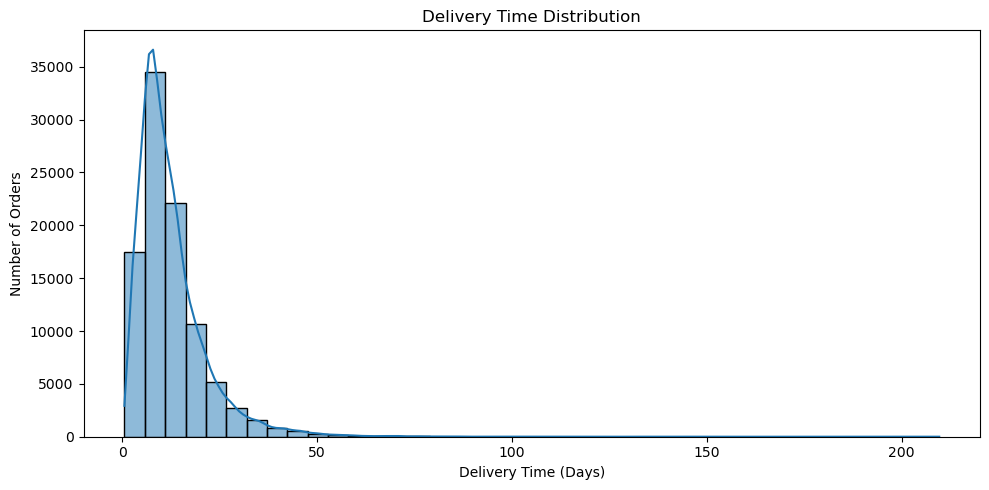

In [62]:
#Delivery Time Distribution – Histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    data=distribution_data,
    x='delivery_time',
    bins=40,
    kde=True
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

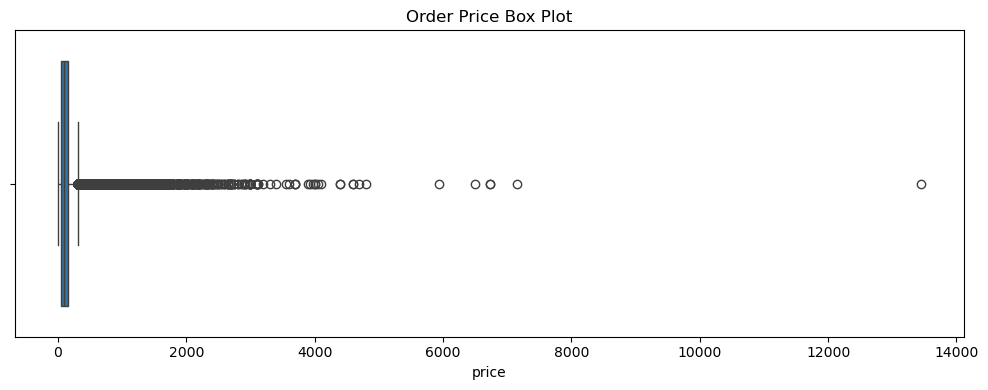

In [63]:
#Price Box Plot

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=distribution_data,
    x='price'
)

plt.title("Order Price Box Plot")
plt.tight_layout()
plt.show()

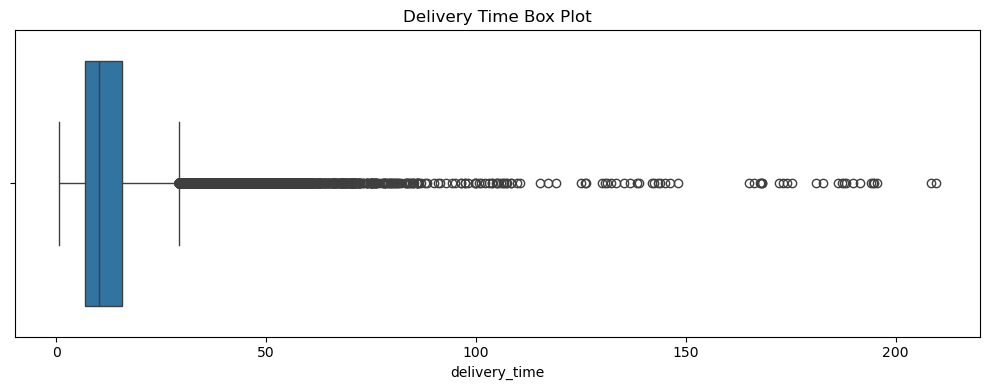

In [64]:
#Freight Box Plot
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=distribution_data,
    x='delivery_time'
)

plt.title("Delivery Time Box Plot")
plt.tight_layout()
plt.show()


In [65]:
#Identify Skewness Use the skew() function to examine whether the distributions are symmetrical.

skewness = distribution_data[
    ['price', 'freight', 'delivery_time']
].skew()

print("Skewness Analysis:")
print(skewness)

Skewness Analysis:
price             9.727741
freight          12.052723
delivery_time     3.832817
dtype: float64


In [66]:
#Identify Potential Outliers Using IQR The Interquartile Range (IQR) method identifies observations outside the usual range.

for col in ['price', 'freight', 'delivery_time']:

    Q1 = distribution_data[col].quantile(0.25)
    Q3 = distribution_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = distribution_data[
        (distribution_data[col] < lower) |
        (distribution_data[col] > upper)
    ]

    print(col, "Potential Outliers:", len(outliers))

price Potential Outliers: 7913
freight Potential Outliers: 9941
delivery_time Potential Outliers: 4899


In [67]:
#Save Analysis Results

import os

os.makedirs('cleaned', exist_ok=True)

distribution_data.to_csv(
    'cleaned/distribution_analysis.csv',
    index=False
)

skewness.to_csv(
    'cleaned/distribution_skewness.csv',
    header=['skewness']
)

print("Distribution analysis completed successfully!")

Distribution analysis completed successfully!
